# Figuras Utilizadas no Capítulo de Resultados do TCC

Este notebook reúne **exclusivamente as 5 figuras utilizadas no capítulo de Resultados (`4-Resultados.tex`)**, padronizadas com o estilo visual limpo padrão do Matplotlib (`plt.style.use("default")`) e formatação numérica PT-BR (vírgula decimal e ponto para milhar):

1. **`boxplot_rpd.pdf` / `.png`** (`fig:boxplot_rpd`): Distribuição do RPD médio por instância — (a) visão global dos 4 algoritmos e (b) zoom competitivo ($\text{RPD} \le 13{,}5\%$).
2. **`boxplot_metaheuristicas.pdf` / `.png`** (`fig:boxplot_metaheuristicas`): Distribuição do RPD das meta-heurísticas (`ILS-VND` e `Santos e Baldotto (2025)`) por conjunto de instâncias (Datasets A, B e X).
3. **`refinamento_ils_vnd.pdf` / `.png`** (`fig:refinamento_ils_vnd`): Redução do RPD pelo refinamento do `ILS-VND` a partir da solução inicial do `AisleBased` nas 22 instâncias com $\text{RPD}(s_0) > 1\%$.
4. **`tradeoff_tempo_qualidade.pdf` / `.png`** (`fig:tradeoff_tempo_qualidade`): Compromisso entre tempo médio de execução e qualidade (RPD médio) em escala bi-logarítmica, com a fronteira de Pareto.
5. **`pedidos_corredores_objetivo.pdf` / `.png`** (`fig:pedidos_corredores_objetivo`): Unidades coletadas, corredores visitados e valor da função objetivo ($f = \text{Unidades}/\text{Corredores}$) nas instâncias `B/0012` e `B/0013` (média de 30 sementes).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import display

# Estilo limpo padrão do Matplotlib
plt.style.use("default")
plt.rcParams.update({
    "figure.dpi": 150,
})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks" / "utils" / "__init__.py").exists())
RESULTS = ROOT / "project" / "results"
BEST_CSV = ROOT / "best_solutions" / "best_objectives.csv"
IMG = ROOT / "notebooks" / "resultados" / "img"; IMG.mkdir(parents=True, exist_ok=True)
TEX = ROOT / "notebooks" / "resultados" / "tex"; TEX.mkdir(parents=True, exist_ok=True)
TEXTO_IMG = ROOT.parent / "Texto" / "Imagens"

DATASETS = ["a", "b", "x"]
ALGOS = {
    "order_based": "OrderBased",
    "aisle_based": "AisleBased",
    "ils_vnd_all": "ILS-VND",
    "andre_feijo_all": "Santos e Baldotto (2025)",
}
NOMES = list(ALGOS.values())
COMPETITIVOS = ["AisleBased", "ILS-VND", "Santos e Baldotto (2025)"]
META = ["ILS-VND", "Santos e Baldotto (2025)"]

# Cores tab10 padrão do Matplotlib
COR = {
    "OrderBased": "#7f7f7f",
    "AisleBased": "#1f77b4",
    "ILS-VND": "#d62728",
    "Santos e Baldotto (2025)": "#2ca02c",
}
MARCADOR = {
    "OrderBased": "s",
    "AisleBased": "^",
    "ILS-VND": "o",
    "Santos e Baldotto (2025)": "D",
}

RNG_SEED = 12345

def vrg(s):
    '''Formata ponto decimal para vírgula (padrão PT-BR).'''
    return str(s).replace(".", ",")

def fmt_num(v, casas=2, sinal=False):
    if pd.isna(v):
        return "—"
    fmt = f"{{:+.{casas}f}}" if sinal else f"{{:.{casas}f}}"
    return vrg(fmt.format(float(v)))

def fmt_milhar(v, casas=0):
    if casas <= 0 or abs(v - round(v)) < 1e-6:
        return f"{int(round(v)):,}".replace(",", ".")
    int_p = int(v)
    dec_p = int(round((v - int_p) * (10 ** casas)))
    return f"{int_p:,}".replace(",", ".") + f",{dec_p:0{casas}d}"

def salvar_tex(nome, linhas):
    texto = "\n".join(linhas) if isinstance(linhas, list) else str(linhas)
    caminho = TEX / f"{nome}.tex"
    caminho.write_text(texto.strip() + "\n", encoding="utf-8")
    print(f"[LaTeX salvo] {caminho.relative_to(ROOT)}")

def salvar_fig(fig, nome, caption, label, width=r"\textwidth"):
    for ext in ("pdf", "png"):
        out_path = IMG / f"{nome}.{ext}"
        fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
        if TEXTO_IMG.exists():
            fig.savefig(TEXTO_IMG / f"{nome}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    bloco = [
        r"\begin{figure}[htbp]",
        r"  \centering",
        rf"  \caption{{{caption}}}",
        rf"  \label{{{label}}}",
        rf"  \includegraphics[width={width}]{{img/{nome}.pdf}}",
        r"  \caption*{\footnotesize Fonte: Elaborado pelo autor, 2026.}",
        r"\end{figure}",
    ]
    salvar_tex(f"fig_{nome}", bloco)
    print(f"[Figura salva] img/{nome}.pdf | img/{nome}.png")

# Carga e validação das 6.000 execuções (50 instâncias x 4 algoritmos x 30 sementes)
frames = []
for folder, label in ALGOS.items():
    for ds in DATASETS:
        for f in sorted((RESULTS / folder / ds).glob("instance_*.csv")):
            d = pd.read_csv(f, usecols=["run_id", "seed", "status", "objective", "items", "aisles", "exec_time"])
            d["algo"], d["dataset"], d["instance"] = label, ds, f.stem + ".txt"
            frames.append(d)
raw = pd.concat(frames, ignore_index=True)
best = pd.read_csv(BEST_CSV).rename(columns={"best_objective": "best"})
raw = raw.merge(best, on=["dataset", "instance"], how="left")

assert (raw["status"] == "feasible").all(), "Há execuções inviáveis!"
assert raw["objective"].notna().all() and raw["best"].notna().all()

raw["rpd"] = (raw["best"] - raw["objective"]) / raw["best"] * 100.0

agg = (
    raw.groupby(["dataset", "instance", "algo"], as_index=False)
    .agg(
        obj_mean=("objective", "mean"),
        obj_dp=("objective", lambda s: s.std(ddof=1)),
        rpd_mean=("rpd", "mean"),
        rpd_dp=("rpd", lambda s: s.std(ddof=1)),
        items_mean=("items", "mean"),
        aisles_mean=("aisles", "mean"),
        tempo_mean=("exec_time", "mean"),
        tempo_dp=("exec_time", lambda s: s.std(ddof=1)),
        best=("best", "first"),
        n=("objective", "size"),
    )
)
assert (agg["n"] == 30).all(), "Todas as instâncias devem ter exatamente 30 seeds!"

def pv(col):
    return agg.pivot(index=["dataset", "instance"], columns="algo", values=col)[NOMES]

OBJ = pv("obj_mean")
RPD = pv("rpd_mean")
RPD_DP = pv("rpd_dp")
ITEMS = pv("items_mean")
AISLES = pv("aisles_mean")
TEMPO = pv("tempo_mean")
BEST = best.set_index(["dataset", "instance"])["best"].reindex(OBJ.index)

N, K = OBJ.shape
ds_idx = OBJ.index.get_level_values("dataset")
print(f"Dados validados: {len(raw)} execuções | N = {N} instâncias | k = {K} algoritmos | 30 seeds/instância.")

Dados validados: 6000 execuções | N = 50 instâncias | k = 4 algoritmos | 30 seeds/instância.


## 1. Figura `boxplot_rpd` — Visão Global e Zoom Competitivo

- **(a) Visão global (4 algoritmos)**: Exibe todas as 50 instâncias. O `OrderBased` concentra-se entre $79{,}6\%$ (Q1) e $94{,}9\%$ (Q3), com média de $81{,}47\%$ e mediana de $88{,}75\%$, tendo como único ponto em $\text{RPD} = 0{,}00\%$ a instância `A/0002` ($f^* = 2{,}00$).
- **(b) Zoom competitivo ($\text{RPD} \le 13{,}5\%$)**: Exibe `AisleBased` (média $3{,}70\%$, mediana $0{,}73\%$, 47 de 50 instâncias visíveis; os 3 *outliers* acima do corte são `A/0009` com $31{,}17\%$, `A/0003` com $29{,}17\%$ e `A/0011` com $24{,}70\%$), `ILS-VND` (média $0{,}18\%$, mediana $0{,}00\%$) e `Santos e Baldotto (2025)` (média $0{,}02\%$, mediana $0{,}00\%$).

[LaTeX salvo] notebooks/resultados/tex/fig_boxplot_rpd.tex
[Figura salva] img/boxplot_rpd.pdf | img/boxplot_rpd.png


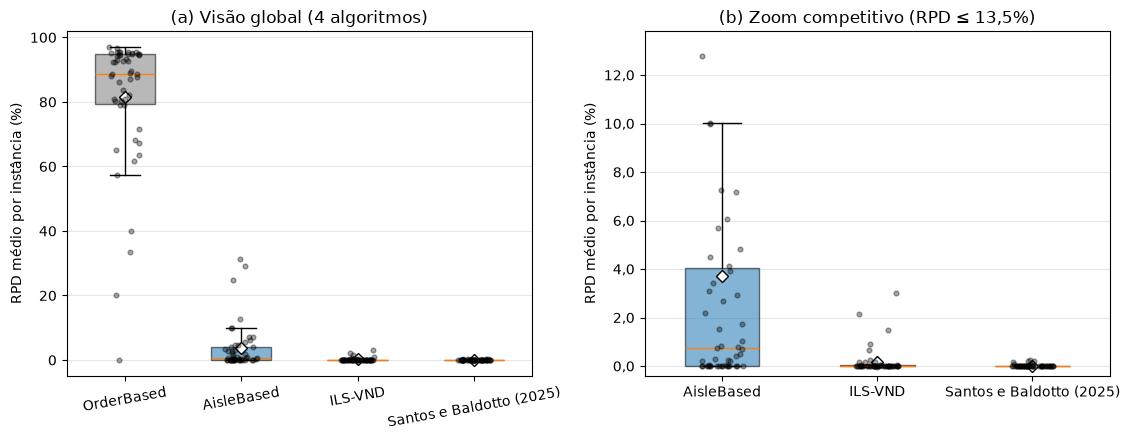

In [2]:
# --- Figura 1: Boxplots de RPD (Visão Global e Zoom Competitivo) ---
with plt.style.context("default"):
    rng_j = np.random.default_rng(RNG_SEED)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), gridspec_kw={"width_ratios": [1.0, 1.0]})

    # (a) Todos os 4 algoritmos
    dados_all = [RPD[a].values for a in NOMES]
    bp0 = axes[0].boxplot(
        dados_all, tick_labels=NOMES, patch_artist=True, showmeans=True, showfliers=False, widths=0.52,
        meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=6),
    )
    for patch, a in zip(bp0["boxes"], NOMES):
        patch.set_facecolor(COR[a])
        patch.set_alpha(0.55)
    for i, a in enumerate(NOMES):
        axes[0].scatter(i + 1 + rng_j.uniform(-0.14, 0.14, N), RPD[a].values, s=12, color="k", alpha=0.35, zorder=3)
    axes[0].set_ylabel("RPD médio por instância (%)")
    axes[0].set_title("(a) Visão global (4 algoritmos)")
    axes[0].grid(alpha=0.3, axis="y")
    axes[0].tick_params(axis="x", rotation=10)

    # (b) Zoom nos 3 algoritmos competitivos
    dados_comp = [RPD[a].values for a in COMPETITIVOS]
    bp1 = axes[1].boxplot(
        dados_comp, tick_labels=COMPETITIVOS, patch_artist=True, showmeans=True, showfliers=False, widths=0.48,
        meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=6),
    )
    for patch, a in zip(bp1["boxes"], COMPETITIVOS):
        patch.set_facecolor(COR[a])
        patch.set_alpha(0.55)
    for i, a in enumerate(COMPETITIVOS):
        vals = RPD[a].values
        mask_in = vals <= 13.5
        axes[1].scatter(i + 1 + rng_j.uniform(-0.14, 0.14, mask_in.sum()), vals[mask_in], s=12, color="k", alpha=0.35, zorder=3)
    axes[1].set_ylim(-0.4, 13.8)
    axes[1].set_ylabel("RPD médio por instância (%)")
    axes[1].set_title("(b) Zoom competitivo (RPD ≤ 13,5%)")
    axes[1].grid(alpha=0.3, axis="y")
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: vrg(f"{y:.1f}")))

    fig.tight_layout()
    salvar_fig(
        fig,
        "boxplot_rpd",
        r"Distribuição do RPD médio por instância (30 sementes): (a) visão global dos quatro algoritmos e (b) zoom competitivo sobre \texttt{AisleBased}, \texttt{ILS-VND} e \texttt{Santos e Baldotto (2025)}. Losangos brancos indicam a média amostral.",
        "fig:boxplot_rpd",
        width=r"0.9\textwidth",
    )
    plt.show()

## 2. Figura `boxplot_metaheuristicas` — Confronto entre Meta-heurísticas por Dataset

- **Dataset A ($N = 20$)**: `ILS-VND` ($\text{média} = 0{,}15\%$, $\text{mediana} = 0{,}00\%$; pontos destacados em `A/0010` $= 2{,}14\%$, `A/0008` $= 0{,}65\%$ e `A/0009` $= 0{,}26\%$) vs. `Santos e Baldotto (2025)` ($\text{média} = 0{,}02\%$, $\text{mediana} = 0{,}00\%$).
- **Dataset B ($N = 15$)**: `ILS-VND` ($\text{média} = 0{,}03\%$, $\text{mediana} = 0{,}00\%$, com valores negativos em `B/0012` $= -0{,}030\%$ e `B/0013` $= -0{,}015\%$) vs. `Santos e Baldotto (2025)` ($\text{média} = 0{,}02\%$, $\text{mediana} = 0{,}00\%$, máximo em `B/0006` $= 0{,}25\%$).
- **Dataset X ($N = 15$)**: `ILS-VND` ($\text{média} = 0{,}38\%$, $\text{mediana} = 0{,}00\%$; pontos destacados em `X/0004` $= 3{,}00\%$, `X/0001` $= 1{,}51\%$ e `X/0015` $= 0{,}90\%$) vs. `Santos e Baldotto (2025)` ($\text{média} = 0{,}02\%$, $\text{mediana} = 0{,}00\%$).

[LaTeX salvo] notebooks/resultados/tex/fig_boxplot_metaheuristicas.tex
[Figura salva] img/boxplot_metaheuristicas.pdf | img/boxplot_metaheuristicas.png


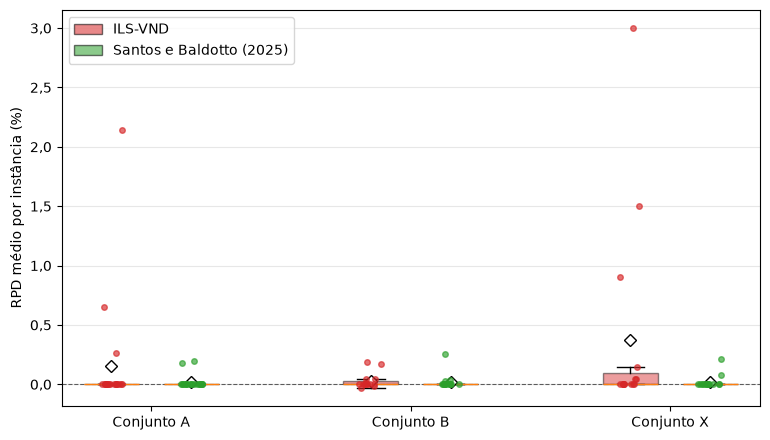

In [3]:
# --- Figura 2: Confronto entre Meta-heurísticas por Dataset ---
with plt.style.context("default"):
    rng_j = np.random.default_rng(RNG_SEED)
    fig, ax = plt.subplots(figsize=(7.8, 4.5))

    dados_meta_ds = []
    cores_meta_ds = []
    xticks_pos, xticks_lab = [], []
    for idx_d, d in enumerate(["a", "b", "x"]):
        sel = ds_idx == d
        p1, p2 = idx_d * 2.6 + 1.0, idx_d * 2.6 + 1.8
        xticks_pos.append((p1 + p2) / 2.0)
        xticks_lab.append(f"Conjunto {d.upper()}")
        for p, a in [(p1, "ILS-VND"), (p2, "Santos e Baldotto (2025)")]:
            vals = RPD.loc[sel, a].values
            dados_meta_ds.append(vals)
            cores_meta_ds.append(COR[a])
            ax.scatter(p + rng_j.uniform(-0.12, 0.12, len(vals)), vals, s=16, color=COR[a], alpha=0.65, zorder=3)

    positions_all = [idx_d * 2.6 + offset for idx_d in range(3) for offset in (1.0, 1.8)]
    bp2 = ax.boxplot(
        dados_meta_ds, positions=positions_all, widths=0.55, patch_artist=True, showmeans=True, showfliers=False,
        meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=6),
    )
    for patch, c in zip(bp2["boxes"], cores_meta_ds):
        patch.set_facecolor(c)
        patch.set_alpha(0.45)

    ax.axhline(0, color="k", lw=0.8, ls="--", alpha=0.6)
    ax.set_xticks(xticks_pos)
    ax.set_xticklabels(xticks_lab)
    ax.set_ylabel("RPD médio por instância (%)")
    ax.grid(alpha=0.3, axis="y")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: vrg(f"{y:.1f}")))

    handles_meta = [
        mpatches.Patch(facecolor=COR["ILS-VND"], edgecolor="k", alpha=0.55, label="ILS-VND"),
        mpatches.Patch(facecolor=COR["Santos e Baldotto (2025)"], edgecolor="k", alpha=0.55, label="Santos e Baldotto (2025)"),
    ]
    ax.legend(handles=handles_meta, loc="upper left", frameon=True)

    fig.tight_layout()
    salvar_fig(
        fig,
        "boxplot_metaheuristicas",
        r"Comparação da distribuição do RPD entre as meta-heurísticas \texttt{ILS-VND} e \texttt{Santos e Baldotto (2025)} por conjunto de instâncias (Datasets A, B e X, médias de 30 sementes). Losangos brancos indicam a média amostral.",
        "fig:boxplot_metaheuristicas",
        width=r"0.75\textwidth",
    )
    plt.show()

## 3. Figura `refinamento_ils_vnd` — Redução do RPD nas 22 Instâncias com $\text{RPD}(s_0) > 1\%$

Demonstra a capacidade de recuperação do `ILS-VND` sobre a solução construtiva `AisleBased` ($s_0$). Das 22 instâncias em que o `AisleBased` apresentava $\text{RPD} > 1\%$, 19 são reduzidas para $\text{RPD} \le 1\%$ (sendo 13 cravadas em $0{,}00\%$), restando apenas `A/0010` ($2{,}14\%$), `X/0004` ($3{,}00\%$) e `X/0001` ($1{,}51\%$) acima de $1\%$.

[LaTeX salvo] notebooks/resultados/tex/fig_refinamento_gvns.tex
[Figura salva] img/refinamento_gvns.pdf | img/refinamento_gvns.png


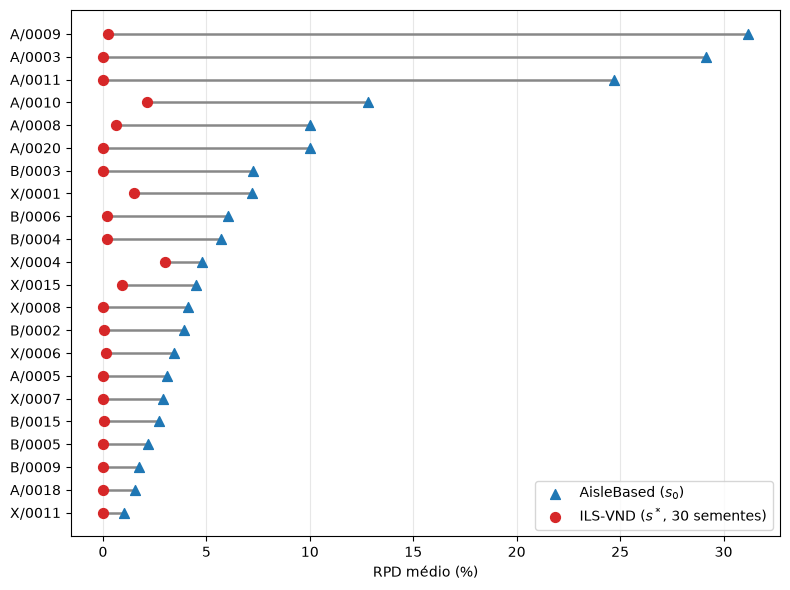

In [4]:
# --- Figura 3: Refinamento AisleBased -> ILS-VND (Dumbbell nas 22 instâncias com RPD inicial > 1%) ---
with plt.style.context("default"):
    df_ref = pd.DataFrame({
        "dataset": OBJ.index.get_level_values("dataset"),
        "instance": OBJ.index.get_level_values("instance"),
        "rpd_aisle": RPD["AisleBased"].values,
        "rpd_ils_vnd": RPD["ILS-VND"].values,
    })
    df_ref["rotulo"] = df_ref["dataset"].str.upper() + "/" + df_ref["instance"].str.replace("instance_", "").str.replace(".txt", "")
    df_gt1 = df_ref[df_ref["rpd_aisle"] > 1.0].sort_values("rpd_aisle", ascending=True).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(8.0, 6.0))

    y_pos = np.arange(len(df_gt1))
    ax.hlines(y_pos, df_gt1["rpd_ils_vnd"], df_gt1["rpd_aisle"], color="#888888", lw=1.8, zorder=2)
    ax.scatter(df_gt1["rpd_aisle"], y_pos, color=COR["AisleBased"], s=50, marker="^", label=r"AisleBased ($s_0$)", zorder=3)
    ax.scatter(df_gt1["rpd_ils_vnd"], y_pos, color=COR["ILS-VND"], s=50, marker="o", label=r"ILS-VND ($s^*$, 30 sementes)", zorder=4)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_gt1["rotulo"])
    ax.set_xlabel("RPD médio (%)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: vrg(f"{x:.0f}")))
    ax.grid(alpha=0.3, axis="x")
    ax.legend(loc="lower right", frameon=True)

    fig.tight_layout()
    salvar_fig(
        fig,
        "refinamento_ils_vnd",
        r"Redução do RPD proporcionada pelo refinamento meta-heurístico do \texttt{ILS-VND} a partir da solução inicial do \texttt{AisleBased} nas 22 instâncias em que o gap inicial excedia $1\%$. Triângulos azuis representam a solução inicial $s_0$; círculos vermelhos indicam a média das soluções finais $s^*$ (30 sementes).",
        "fig:refinamento_ils_vnd",
        width=r"0.75\textwidth",
    )
    plt.show()

## 4. Figura `tradeoff_tempo_qualidade` — Compromisso Tempo de Execução $\times$ Qualidade (RPD)

Exibe em escala bi-logarítmica a relação entre o tempo médio de execução (s) e o RPD médio (%) por conjunto de instâncias (`A`, `B`, `X`) e no consolidado (`Geral`). O `OrderBased` ($15{,}92\text{ s}$, $81{,}47\%$) é estritamente dominado pelo `AisleBased` ($2{,}02\text{ s}$, $3{,}70\%$). A fronteira de Pareto amostral conecta `AisleBased` e `Santos e Baldotto (2025)` ($190{,}77\text{ s}$, $0{,}02\%$), enquanto o `ILS-VND` ($475{,}28\text{ s}$, $0{,}18\%$) utiliza o orçamento configurado de $590\text{ s}$ nas instâncias de maior porte.

[LaTeX salvo] notebooks/resultados/tex/fig_tradeoff_tempo_qualidade.tex
[Figura salva] img/tradeoff_tempo_qualidade.pdf | img/tradeoff_tempo_qualidade.png


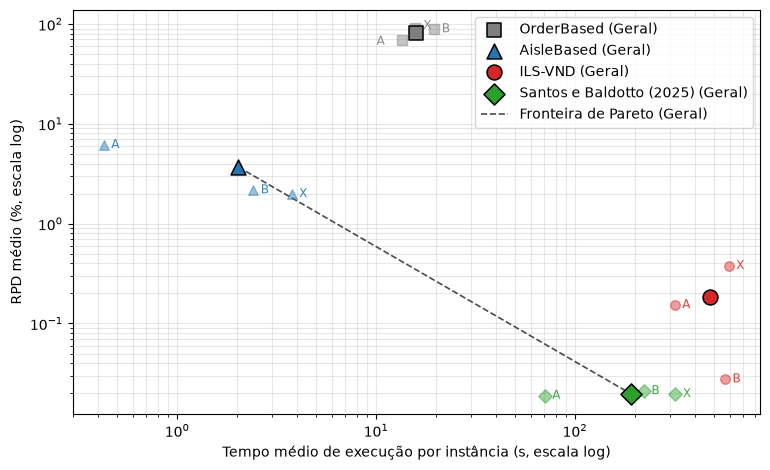

In [5]:
# --- Figura 4: Compromisso Tempo de Execução x Qualidade (RPD) ---
with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(7.8, 4.8))

    offsets_ds = {
        ("OrderBased", "a"): (0.82, 0.96, "right"),
        ("OrderBased", "b"): (1.10, 1.00, "left"),
        ("OrderBased", "x"): (1.10, 1.06, "left"),
    }

    for a in NOMES:
        for d in ["a", "b", "x"]:
            sel = ds_idx == d
            tm = TEMPO.loc[sel, a].mean()
            rm = RPD.loc[sel, a].mean()
            ax.scatter(tm, rm, color=COR[a], marker=MARCADOR[a], s=48, alpha=0.45, zorder=3)
            fx, fy, ha_align = offsets_ds.get((a, d), (1.09, 1.00, "left"))
            ax.text(tm * fx, rm * fy, d.upper(), fontsize=8.5, color=COR[a], alpha=0.9, va="center", ha=ha_align)

        tm_g = TEMPO[a].mean()
        rm_g = RPD[a].mean()
        ax.scatter(tm_g, rm_g, color=COR[a], marker=MARCADOR[a], s=115, edgecolor="k", lw=1.1, label=f"{a} (Geral)", zorder=5)

    pareto_t = [TEMPO["AisleBased"].mean(), TEMPO["Santos e Baldotto (2025)"].mean()]
    pareto_r = [RPD["AisleBased"].mean(), RPD["Santos e Baldotto (2025)"].mean()]
    ax.plot(pareto_t, pareto_r, color="k", ls="--", lw=1.2, alpha=0.7, label="Fronteira de Pareto (Geral)")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Tempo médio de execução por instância (s, escala log)")
    ax.set_ylabel("RPD médio (%, escala log)")
    ax.grid(alpha=0.3, which="both")
    ax.legend(loc="upper right", frameon=True)

    fig.tight_layout()
    salvar_fig(
        fig,
        "tradeoff_tempo_qualidade",
        r"Compromisso entre tempo médio de execução e qualidade da solução (RPD médio) em escala bi-logarítmica por conjunto de instâncias (Datasets A, B e X) e consolidado (Geral, 30 sementes). A linha tracejada demarca a fronteira de Pareto amostral.",
        "fig:tradeoff_tempo_qualidade",
        width=r"0.75\textwidth",
    )
    plt.show()

## 5. Figura `pedidos_corredores_objetivo` — Unidades Coletadas, Corredores Visitados e Função Objetivo (`B/0012` e `B/0013`)

**Correções aplicadas conforme revisão**:
1. **Terminologia exata**: A coluna `items` representa **unidades coletadas** ($\lvert\mathcal{O}'\rvert$, numerador de $f = \text{Unidades}/\text{Corredores}$), corrigindo os rótulos dos eixos, legenda, título e *caption* LaTeX.
2. **Ordem padronizada dos algoritmos**: `OrderBased`, `AisleBased`, `ILS-VND` e `Santos e Baldotto (2025)`, mantendo a mesma sequência de todas as tabelas e figuras do TCC.
3. **Precisão aritmética na instância `B/0012`**: O `ILS-VND` coleta em média $6.245{,}9$ unidades em $11$ corredores ($6.245{,}9 / 11 = 567{,}81$), diferenciando-se explicitamente das $6.244$ unidades ($f = 567{,}64$) de `AisleBased` e `Santos e Baldotto (2025)`.

[LaTeX salvo] notebooks/resultados/tex/fig_pedidos_corredores_objetivo.tex
[Figura salva] img/pedidos_corredores_objetivo.pdf | img/pedidos_corredores_objetivo.png


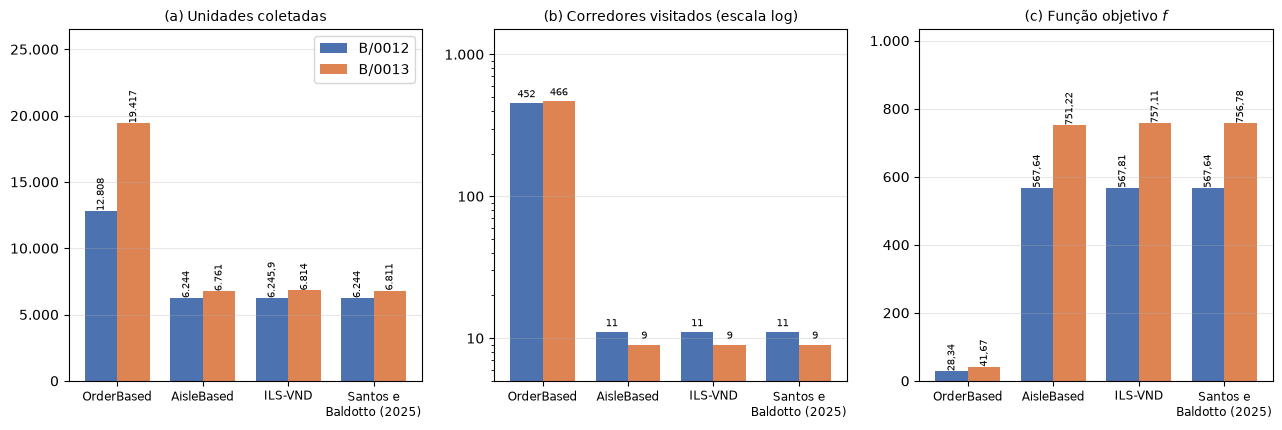

In [6]:
# --- Figura 5: Unidades coletadas, corredores visitados e função objetivo (B/0012 e B/0013) ---
ALGOS_ORDEM = ["OrderBased", "AisleBased", "ILS-VND", "Santos e Baldotto (2025)"]
ROTULOS_X = ["OrderBased", "AisleBased", "ILS-VND", "Santos e\nBaldotto (2025)"]
INST = [("instance_0012.txt", "B/0012", "#4c72b0"), ("instance_0013.txt", "B/0013", "#dd8452")]
with plt.style.context("default"):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
    x = np.arange(len(ALGOS_ORDEM)); w = 0.38
    metricas = [("items", "(a) Unidades coletadas", False, 0),
                ("aisles", "(b) Corredores visitados (escala log)", True, 0),
                ("objective", r"(c) Função objetivo $f$", False, 2)]
    for ax, (col, titulo, logy, casas) in zip(axes, metricas):
        for j, (inst_id, rot, cor) in enumerate(INST):
            sub = raw[(raw["dataset"] == "b") & (raw["instance"] == inst_id)]
            vals = [sub[sub["algo"] == a][col].mean() for a in ALGOS_ORDEM]
            bars = ax.bar(x + (j - 0.5) * w, vals, w, color=cor, label=rot)
            for b, v in zip(bars, vals):
                c = casas if col == "objective" else (1 if abs(v - round(v)) > 1e-4 else 0)
                txt = fmt_num(v, c) if col == "objective" else fmt_milhar(v, c)
                ax.text(b.get_x() + b.get_width() / 2, v * (1.06 if logy else 1.0),
                        txt, ha="center", va="bottom", fontsize=7.5, rotation=90 if col != "aisles" else 0)
        if logy:
            ax.set_yscale("log"); ax.set_ylim(5, 1500)
        else:
            ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
        ax.set_xticks(x); ax.set_xticklabels(ROTULOS_X, fontsize=8.5)
        ax.set_title(titulo, fontsize=10)
        ax.grid(alpha=0.3, axis="y")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: fmt_milhar(y, 0) if y >= 1 else vrg(f"{y:g}")))
    axes[0].legend(loc="upper right", frameon=True)
    fig.tight_layout()
    salvar_fig(
        fig,
        "pedidos_corredores_objetivo",
        r"Unidades coletadas (a), corredores visitados (b, em escala logarítmica) e valor da função objetivo $f = \text{unidades}/\text{corredores}$ (c) por algoritmo nas instâncias B/0012 e B/0013 (média de 30 sementes).",
        "fig:pedidos_corredores_objetivo",
        width=r"0.98\textwidth",
    )
    plt.show()
